# Data reduction

In [ ]:
%matplotlib widget
import Miracles_Reduction as MR
import scipp as sc
import time
import matplotlib.pyplot as plt
import plopp as pp
import os
import numpy as np
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{upgreek}",
})

start = time.time()

In [2]:

# ----------------------------
# Example usage
# ----------------------------
bins={'hw':sc.linspace('hw',-100,500,num=1000,unit='ueV'),
                  'qval':sc.linspace('qval',0.2,2,num=10,unit="1/Angstrom")}
'''
#path='/Users/christianbeck/Library/CloudStorage/OneDrive-esss.se/McStasMiracles/05_multipulse/'
path='/Users/christianbeck/scratchmount/mountpointscratch/Miracles/Miracles-McStas/'
reduction = MR.Reduction(
    sample_file=[path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],
    background_file=['Bkg',path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],
    vanadium_file=['Vana',path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],
    scale=0,
    bins=bins,
    ReductionFolder='Reduction_Files_hires/'
)
'''

"\n#path='/Users/christianbeck/Library/CloudStorage/OneDrive-esss.se/McStasMiracles/05_multipulse/'\npath='/Users/christianbeck/scratchmount/mountpointscratch/Miracles/Miracles-McStas/'\nreduction = MR.Reduction(\n    sample_file=[path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],\n    background_file=['Bkg',path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],\n    vanadium_file=['Vana',path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],\n    scale=0,\n    bins=bins,\n    ReductionFolder='Reduction_Files_hires/'\n)\n"

In [3]:
#reduction.save_intermediate(['RawData[Sample]','convertedUnits[Sample]'])

In [4]:
# Visualize
#reduction.visualize('Reduction_Workflow')

In [5]:
#Res=reduction.run()

In [6]:
import json
import h5py
import scipp as sc
import tempfile
import os


def loadhdf(filename):
    """
    Load a dictionary from an HDF5 file created with savehdf().

    Returns
    -------
    dict
        Dictionary containing Scipp objects and normal Python objects.
    """

    result = {}

    with h5py.File(filename, "r") as f:

        for key in f.keys():

            grp = f[key]

            # Case 1: non-Scipp object stored as attribute
            if "value" in grp.attrs:

                value = grp.attrs["value"]

                # h5py may return bytes
                if isinstance(value, bytes):
                    value = value.decode()

                # Try JSON decode first
                try:
                    result[key] = json.loads(value)
                except Exception:
                    # fallback: plain string
                    result[key] = value

            # Case 2: Scipp object
            else:
                # sc.io.load_hdf5 expects a file, not a subgroup,
                # so recreate temporary file from subgroup
                fd, tmpname = tempfile.mkstemp(suffix=".hdf5")
                os.close(fd)

                try:
                    with h5py.File(tmpname, "w") as tmpf:

                        def copyall(srcnode, dstnode):
                            for name, item in srcnode.items():
                                srcnode.copy(name, dstnode, name=name)

                            for attr in srcnode.attrs:
                                dstnode.attrs[attr] = srcnode.attrs[attr]

                        copyall(grp, tmpf)

                    result[key] = sc.io.load_hdf5(tmpname)

                finally:
                    os.remove(tmpname)

    return result

#####load several files
['./files/gamma_hires_0/', './files/gamma_hires_0_0/', './files/gamma_hires_0_1/', './files/gamma_hires_0_2/', './files/gamma_hires_0_3/', './files/gamma_hires_0_4/', './files/gamma_hires_0_5/', './files/gamma_hires_0_6/', './files/gamma_hires_0_7/', './files/gamma_hires_0_8/', './files/gamma_hires_0_9/', './files/gamma_hires_0_10/', './files/gamma_hires_0_11/', './files/gamma_hires_0_12/', './files/gamma_hires_0_13/', './files/gamma_hires_0_14/', './files/gamma_hires_0_15/', './files/gamma_hires_0_16/', './files/gamma_hires_0_17/', './files/gamma_hires_0_18/', './files/gamma_hires_0_19/', './files/gamma_hires_0_20/', './files/gamma_hires_0_21/', './files/gamma_hires_0_22/', './files/gamma_hires_0_23/', './files/gamma_hires_0_24/', './files/gamma_hires_0_25/', './files/gamma_hires_0_26/', './files/gamma_hires_0_27/', './files/gamma_hires_0_28/', './files/gamma_hires_0_29/', './files/gamma_hires_0_30/', './files/gamma_hires_0_31/', './files/gamma_hires_0_32/', '.

/Users/christianbeck/Documents/Miracles/Data Reduction/version7_detector tube resolution testing hires local files/Miracles_Reduction_v7.py:483: UserWarning: Assuming McStas results from Miracles with detector tubes from monitornd 
 Assuming the following entries: Intensity Wavelength Time_Of_Flight Position
  warnings.warn('Assuming McStas results from Miracles with detector tubes from monitornd \n Assuming the following entries: Intensity Wavelength Time_Of_Flight Position')


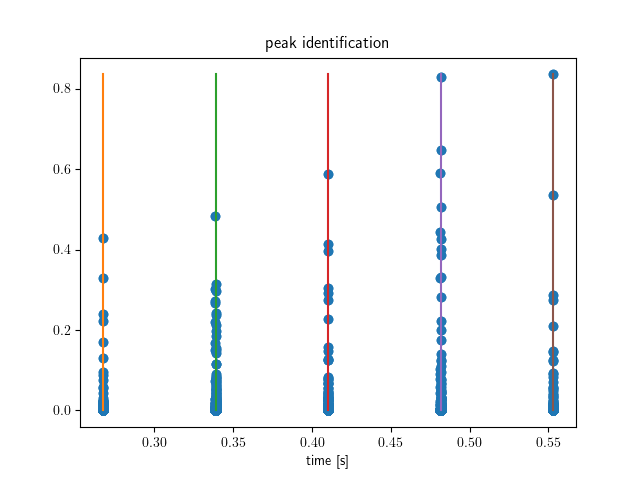

#####save monitornormalization values
detected centers: [0.26732777 0.33883964 0.410263   0.48166377 0.55308875]
Monitor from nexus file loaded!


/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


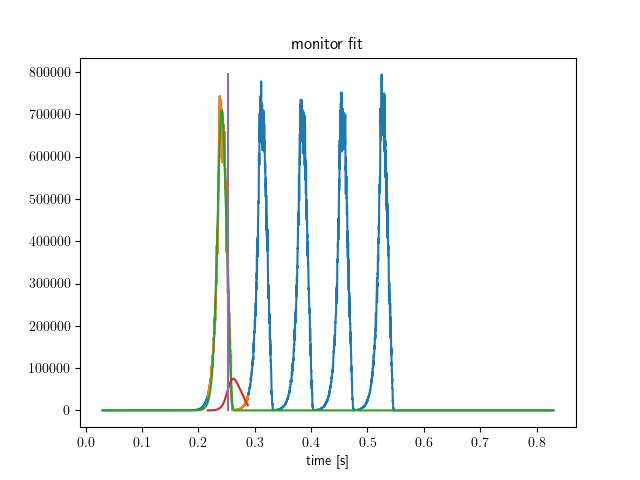

/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/christianbeck/Documents/Miracles/Data Reduction/version7_detector tube resolution testing hires local files/Miracles_Reduction_v7.py:483: UserWarning: Assuming McStas results from Miracles with detector tubes from monitornd 
 Assuming the following entries: Intensity Wavelength Time_Of_Flight Position
  warnings.warn('Assuming McStas results from Miracles with detector tubes from monitornd \n Assuming the following entries: Intensity Wavelength Time_Of_Flight Position')


nexus file found and loaded
./files/gamma_hires_0_0/
neutrons reduced from (24348,) events to (24348,) events
100
[0.2672434  0.2672434  0.26724368 ... 0.55334874 0.55335561 0.55335561]
[100 100 100 ... 100 100 100]
[8.00956184e-07 8.00956184e-07 7.67040374e-07 ... 6.29591124e-07
 6.93986403e-07 6.93986403e-07]
#####save monitornormalization values
detected centers: [0.26743182 0.33885734 0.4102692  0.48170296 0.55311392]
Monitor from nexus file loaded!


/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


nexus file found and loaded
./files/gamma_hires_0_1/
neutrons reduced from (24316,) events to (24316,) events
100
[0.26726646 0.26726646 0.26726673 ... 0.55335334 0.55336684 0.55336684]
[100 100 100 ... 100 100 100]
[9.11428399e-07 9.11428399e-07 8.44358285e-07 ... 6.92483454e-07
 8.19022381e-07 8.19022381e-07]
#####save monitornormalization values
detected centers: [0.26743068 0.33886257 0.41028752 0.48171683 0.55313202]
Monitor from nexus file loaded!


/Users/christianbeck/Documents/Miracles/Data Reduction/version7_detector tube resolution testing hires local files/Miracles_Reduction_v7.py:483: UserWarning: Assuming McStas results from Miracles with detector tubes from monitornd 
 Assuming the following entries: Intensity Wavelength Time_Of_Flight Position
  warnings.warn('Assuming McStas results from Miracles with detector tubes from monitornd \n Assuming the following entries: Intensity Wavelength Time_Of_Flight Position')
/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/christianbeck/miniforge3/envs/mcstas/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/christianbeck/Documents/Miracles/Data Reduction/version7_detector tube resolution testing hires local files/Miracles_Red

...

nexus file found and loaded
Merging 41 folder(s)
#####transformation_coordinates
#####artificially coarsening the detector tube to a resolution of 2 bin(s)


100%|██████████| 1002978/1002978 [02:03<00:00, 8137.15it/s]


#####transformation_coordinates
#####artificially coarsening the detector tube to a resolution of 2 bin(s)


100%|██████████| 1002978/1002978 [02:02<00:00, 8206.17it/s]


#####binning
#####binning
#####Vanapeak
#####Peakcenters loaded
center by mean value of vanadium peaks of q values
start saveing routine


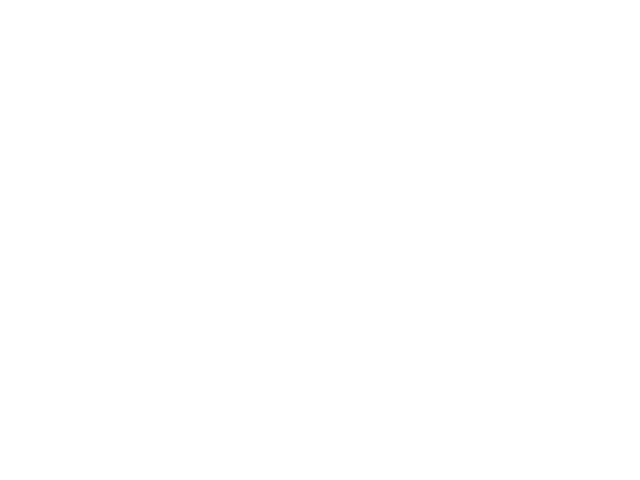

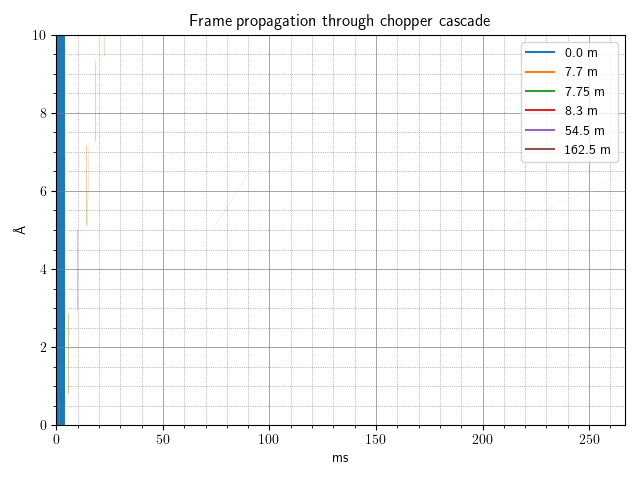

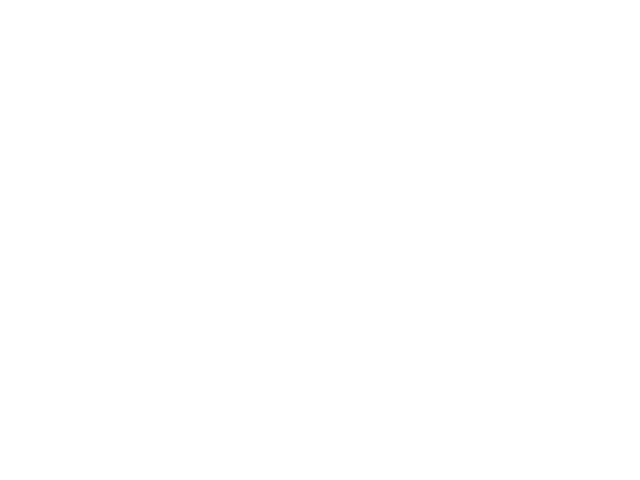

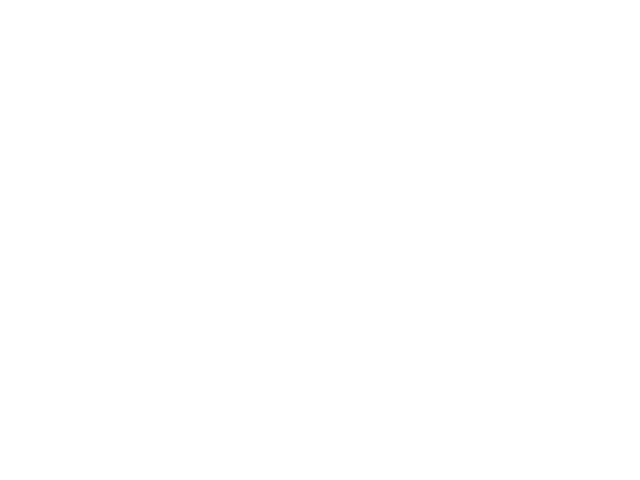

In [7]:
Nbins=range(1,10)
Result={}

if os.path.isfile('binningdata.hdf'):
    res=loadhdf('binningdata.hdf')
else:
    res={}
for detres in Nbins:
    if  detres==2 or f"reduceddata{detres}" not in res.keys():
        MR.debugging_dettube=detres

        path='./files/'
        reduction = MR.Reduction(
            sample_file=[path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],
            background_file=['Bkg',path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],
            vanadium_file=['Vana',path+'gamma_hires_0/']+[path+f'gamma_hires_0_{hi}/' for hi in range(40)],
            scale=0,
            bins=bins,
            ReductionFolder='Reduction_Files_hires/'
        )
        # reduction = MR.Reduction(
        # sample_file=[path+'samples_fQE0_ftun0gamma0/'],
        # background_file=['Bkg',path+'samples_fQE0_ftun0gamma0/'],
        # vanadium_file=['Vana',path+'samples_fQE0_ftun0gamma0/'],
        # scale=0,
        # bins=bins
        # )
        reduction.save_intermediate(['RawData[Sample]','convertedUnits[Sample]'])
        Result.update({f"reduceddata{detres}":reduction.run()})
        res.update({f"reduceddata{detres}":Result[f"reduceddata{detres}"]['data'].hist().transpose()})
        MR.Reduction.savehdf(res,'binningdata.hdf')


In [8]:
end = time.time()
print(f'Calculation took {end - start:.2f} seconds')

Calculation took 493.39 seconds


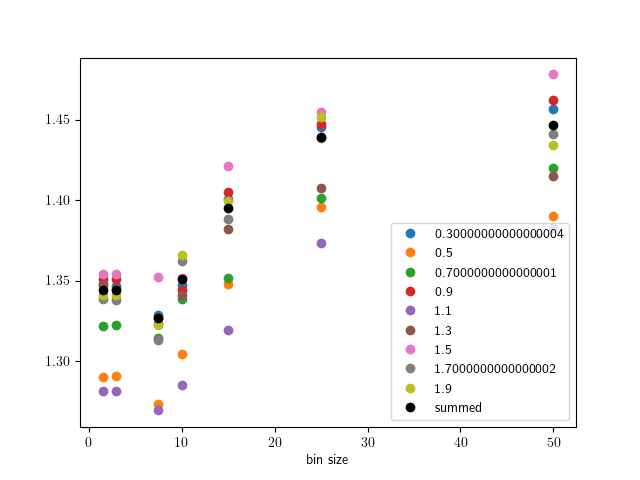

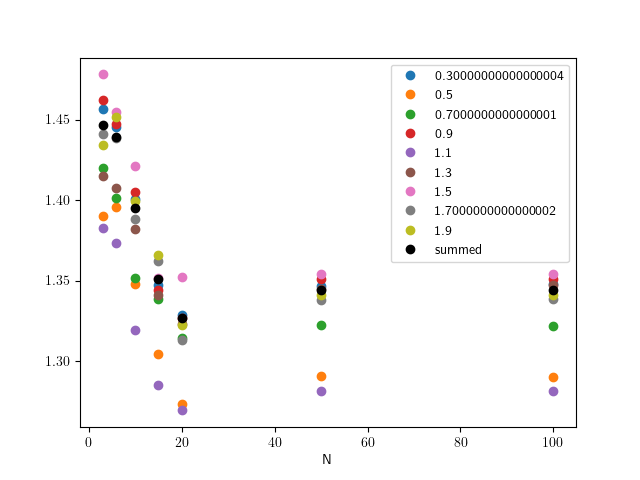

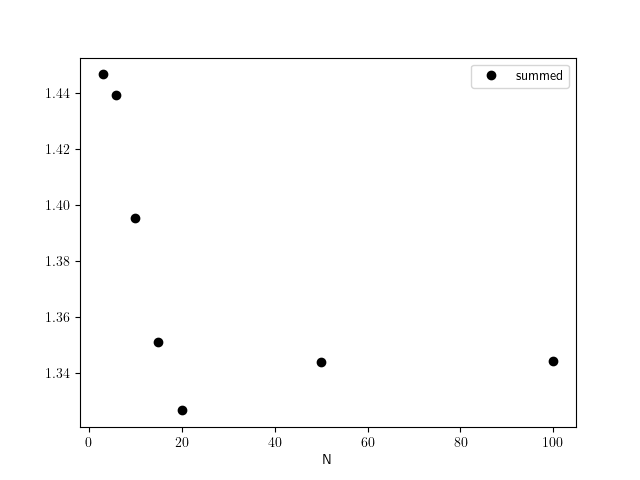

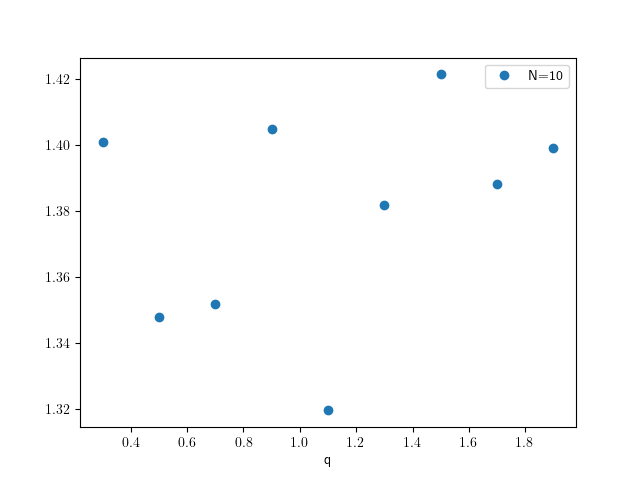

In [26]:
avoid=[1,2,4,5,7,8,9]
d={'binning':[],'centroid':[],'variance':[]}
C=[]
V=[]
for r in res:
    if int(r.replace('reduceddata','')) not in avoid:
        d['binning'].append(int(r.replace('reduceddata','')))
        centroid=[]
        variance=[]
        q=res[r].coords['qval'].values
        q=(q[1:]+q[:-1])/2
        for hiq,qv in enumerate(q):
            x=res[r].coords['hw'].values
            x=(x[1:]+x[:-1])/2
            y=res[r].data['qval',hiq].values
            centroid.append(np.sum(x*y)/np.sum(y))
            variance.append(np.sum(y*(x-centroid[-1])**2)/np.sum(y))
        Y=res[r].sum(dim='qval').values
        C.append(np.sum(x*Y)/np.sum(Y))
        V.append(np.sum(Y*(x-C[-1])**2)/np.sum(Y))
        d['centroid'].append(centroid)
        d['variance'].append(variance)
plt.figure()
plt.plot(150/np.array(d['binning']),np.array(d['variance'])**0.5,'o',label=q)
plt.plot(150/np.array(d['binning']),np.array(V)**0.5,'ko',label='summed')
plt.xlabel('bin size')
plt.legend()

plt.figure()
plt.plot(np.array(d['binning']),np.array(d['variance'])**0.5,'o',label=q)
plt.plot(np.array(d['binning']),np.array(V)**0.5,'ko',label='summed')
plt.xlabel('N')
plt.legend()

plt.figure()
plt.plot(np.array(d['binning']),np.array(V)**0.5,'ko',label='summed')
plt.xlabel('N')
plt.legend()

hib=0
plt.figure()
plt.plot(q,[np.sqrt(v) for v in d['variance'][hib]],'o',label=f'N={d['binning'][hib]}')
plt.xlabel('q')
plt.legend()


In [10]:
a=np.array([int(k.replace('reduceddata','')) for k in res.keys()])
a.sort()
a


array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  15,  20,  50,
       100])

In [11]:
def crossings(x,y):
    target = 0.5

    # Difference from target
    d = y - target

    # Find indices where sign changes
    idx = np.where(np.diff(np.sign(d)) != 0)[0]

    # Linear interpolation for crossing points
    x_crossings = []

    for i in idx:
        x1, x2 = x[i], x[i+1]
        y1, y2 = y[i], y[i+1]

        # interpolate x at y=0.5
        x_cross = x1 + (target - y1) * (x2 - x1) / (y2 - y1)
        x_crossings.append(x_cross)
    return x_crossings

<>:20: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
<>:20: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
/Users/christianbeck/tmp/ipykernel_26503/4032927835.py:20: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
  ax1[qidx].set_title(f'q= {res['reduceddata1'].coords['qval'].values[qidx]:.1f}'+' \AA$^{-1}$')


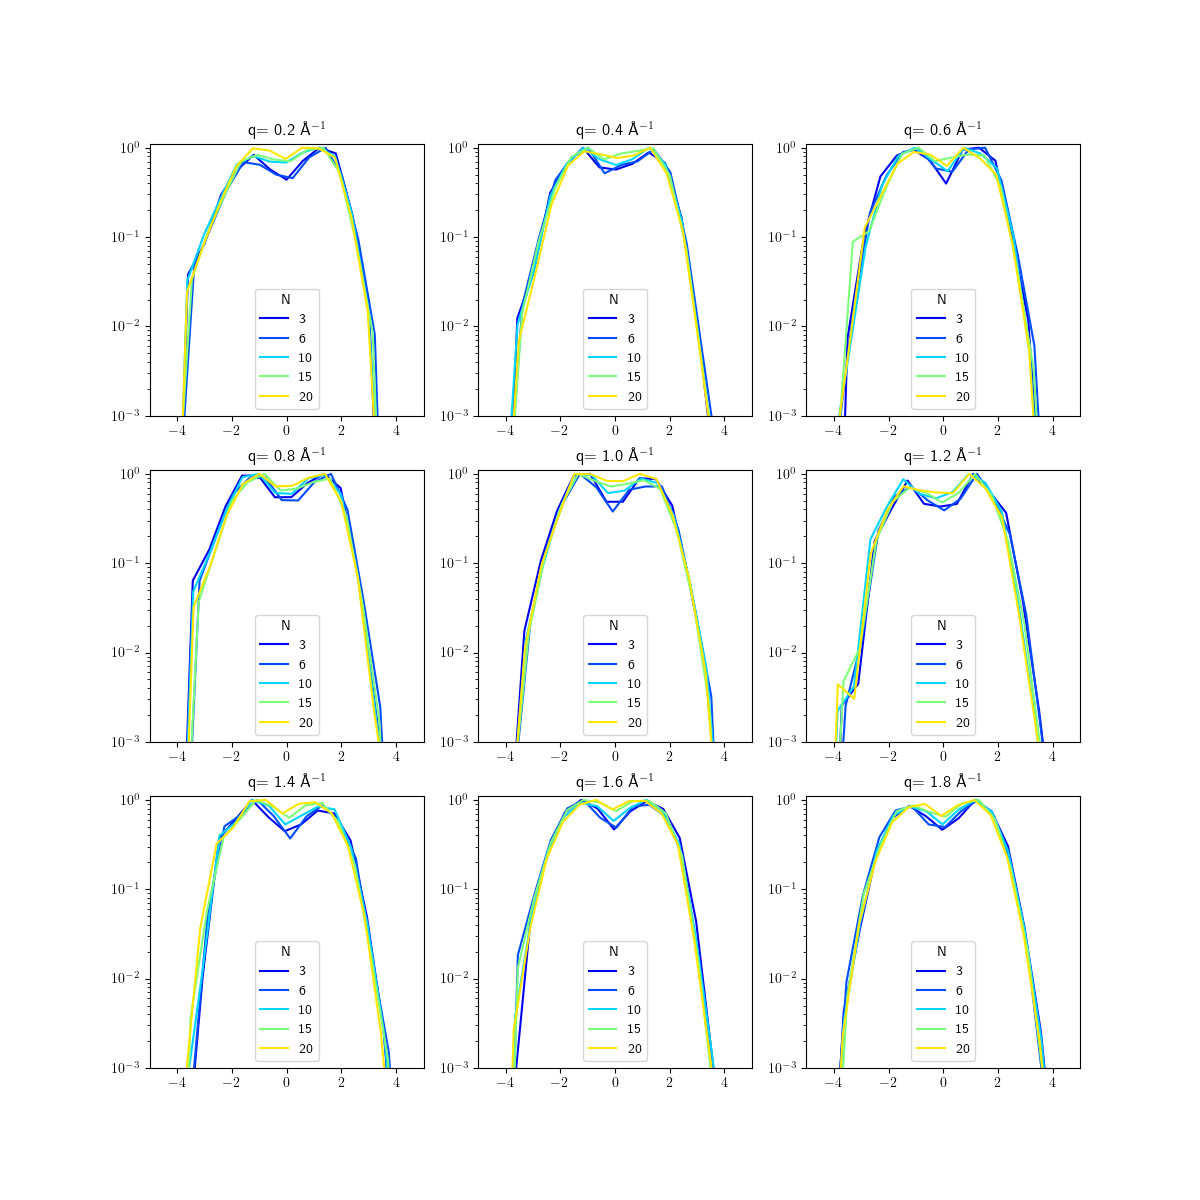

In [30]:
import matplotlib as mpl
cmap = mpl.colormaps['jet']
spectrabins=range(1,22)

fig1,ax1=plt.subplots(3,3,figsize=(12,12))
ax1=ax1.flatten().tolist()
for qidx in range(9):
    for sb in spectrabins:
        if (sb not in avoid) and f'reduceddata{sb}' in res.keys():
            x=res['reduceddata1'].coords['hw'].values
            x=(x[:-1]+x[1:])/2
            y=res[f'reduceddata{sb}'].data.values[qidx,:]
            y=y/max(y)
            crossings(x,y)
            ax1[qidx].plot(x-np.mean(crossings(x,y)),y,label=sb,color=cmap(sb/30))
    ax1[qidx].legend(title='N')
    ax1[qidx].set_yscale('log')
    ax1[qidx].set_ylim(0.001,1.1)
    ax1[qidx].set_xlim(-5,5)
    ax1[qidx].set_title(f'q= {res['reduceddata1'].coords['qval'].values[qidx]:.1f}'+' \AA$^{-1}$')

In [15]:
pp.plot(res['reduceddata3'])

InteractiveFigure(children=(HBar(), HBar(children=(VBar(children=(Toolbar(children=(ButtonTool(icon='home', la…

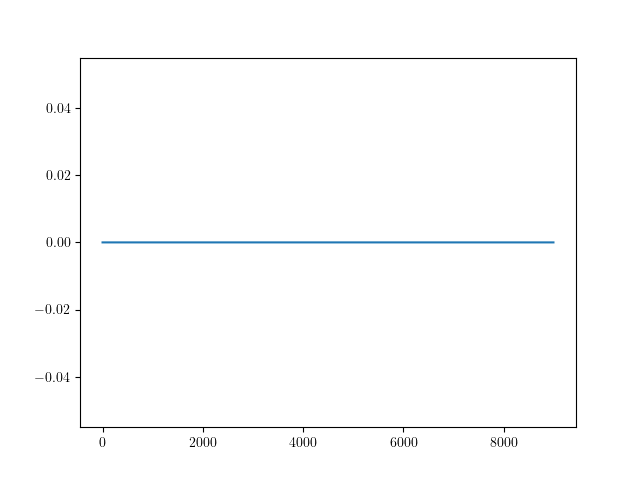

In [23]:
binned=res['reduceddata2']
unbinned = sc.flatten(binned, to='event')
plt.figure()
plt.plot(unbinned.data.values)
